In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import torch
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN

In [2]:
import sys
import os
import cv2
from pathlib import Path
sys.path.insert(0, str(Path().resolve().parent.parent.parent))

# Now your imports will work
from assessment.vIAbility.data.dataset import build_labels, load_metadata, parse_video_name
from sklearn.model_selection import train_test_split
from config.config import SEED, PARAM_GRID, PATH_DATASET

In [3]:
%cd ../../../

/home/mvillota/Documentos/Tesis/EmbryoDev_Assess


In [ ]:
class FEMIDataset:
    def __init__(self, files: list[str], labels: list[int]):
        self.files  = files
        self.labels = labels

    def __len__(self) -> int:
        return len(self.files)

    def __getitem__(self, idx: int):
        data = torch.load(self.files[idx], map_location="cpu", weights_only=True)
        filename = os.path.basename(self.files[idx])
        x    = data["embeddings"].float()   # (T, embed_dim)
        mask = data["mask"].bool()          # (T,)  True = valid frame
        frames = data["frames"].long()          # (T,)  frame numbers
        y    = torch.tensor(self.labels[idx], dtype=torch.float32)
        return filename, x, mask, frames, y

In [5]:
def build_datasets(
    feature_dir: str,
    excel_path:  str,
    test_size = 0.2,
    seed= SEED,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    df        = pd.read_excel(excel_path)
    all_files = sorted([os.path.join(feature_dir, f)for f in os.listdir(feature_dir) if f.endswith(".pt")])
    namefiles = [os.path.basename(f) for f in all_files]
    labels    = build_labels(namefiles, df)

    train_files, val_files, y_train, y_val = train_test_split(
        all_files, labels,
        test_size=test_size,
        stratify=labels,
        random_state=seed,
    )

    train_dataset = FEMIDataset(train_files, y_train)
    val_dataset   = FEMIDataset(val_files, y_val)
    X_train_files, X_test_files = [], []
    X_train, mask_train, y_train = [], [], []
    X_val, mask_val, y_val = [], [], []
    for i in range(len(train_dataset)):
        filename, x, mask, y = train_dataset[i]
        X_train_files.append(filename)
        X_train.append(x)
        mask_train.append(mask)
        y_train.append(y)
    for i in range(len(val_dataset)):
        filename, x, mask, y = val_dataset[i]
        X_test_files.append(filename)
        X_val.append(x)
        mask_val.append(mask)
        y_val.append(y)
    X_train = torch.stack(X_train)        # (N_train, T, embed_dim)
    mask_train = torch.stack(mask_train)  # (N_train, T)
    y_train = torch.stack(y_train)        # (N_train,)
    X_val = torch.stack(X_val)            # (N_val, T, embed_dim)
    mask_val = torch.stack(mask_val)      # (N_val, T)
    y_val = torch.stack(y_val)            # (N_val,)


    return (X_train_files, X_train, mask_train, y_train), (X_test_files, X_val, mask_val, y_val)

In [6]:
def plot_explained_variance(pca):
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), 
             np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--')

    plt.title('Accumulated Explained Variance by PCA Components')
    plt.xlabel('Number of Components')
    plt.ylabel('Accumulated Explained Variance')
    plt.grid()
    plt.show()

In [7]:
feature_dir = os.path.join(PATH_DATASET, "Oslo_processed/femi_features")
excel_path = os.path.join(PATH_DATASET, "Oslo_processed/Oslo_completo.xlsx")

In [8]:
(train_files, X_train, mask_train, y_train), (X_test_files, X_val, mask_val, y_val) = build_datasets(feature_dir, excel_path, 0.2, SEED)

In [9]:
def tensors_to_lists(X, mask):
    return list(X), list(mask)

X_train, mask_train = tensors_to_lists(X_train, mask_train)
X_val, mask_val = tensors_to_lists(X_val, mask_val)

In [10]:
def get_frame(excel_path, video_file, t):
    df = load_metadata(excel_path)
    vid_id, well = parse_video_name(video_file)
    rows = df[(df["ID"] == vid_id) & (df["Well"] == well)]
    tse        = rows["Tse"].iloc[0]
    frame_hour = rows["frame_hour"].iloc[0]
    frame_idx = int((t - tse) * frame_hour)
    return frame_idx

In [11]:
def image_frame(file,excel_path, t=0):
    video_path = os.path.join(PATH_DATASET, "Oslo_processed/videos/", file.replace(".pt", ".avi"))
    cap = cv2.VideoCapture(video_path)
    frame_idx = get_frame(excel_path, file, t)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    _, image = cap.read()
    cap.release()
    return image

In [12]:
def frame_ext(train_files, X_train, X_train_mask, y_train, t=0):
    frame_data = {'files':[], 'tensores':[], 'labels':[]}
    for i in range(len(X_train)):
        if X_train_mask[i][t]:  # Solo consideramos los frames válidos
            frame_data['files'].append(train_files[i])
            frame_data['tensores'].append(X_train[i][t].numpy())
            frame_data['labels'].append(y_train[i].item())
    return frame_data

In [13]:
def plot_pca(frame, pca_components=2, i = 0, j=1, paint = 'labels'):
    pca = PCA(n_components=pca_components)
    pca.fit(frame['tensores'])
    try:
        unique_labels = np.unique(frame[paint])
    except:
        print('paint must be a valid key in the frame dictionary')
    dict_color = {label: plt.cm.tab10(i) for i, label in enumerate(unique_labels)}
    colors = [dict_color.get(label, 'gray') for label in frame[paint]]
    X_pca = pca.transform(frame['tensores'])

    plt.figure(figsize=(8, 6))
    plt.scatter(X_pca[:, i], X_pca[:, j], c=colors, alpha=0.7)
    plt.xlabel(f'PC{i+1} ({pca.explained_variance_ratio_[i]:.2%} variance)')
    plt.ylabel(f'PC{j+1} ({pca.explained_variance_ratio_[j]:.2%} variance)')
    plt.title('Proyection of the data in the first two components')
    plt.grid()
    plt.show()
    return pca

### Frames in `t`
Frames in moment in `t` from all the videos are selected. 
We want to study if we are able to identify the different stages of the embryo. 

In [14]:
frames = frame_ext(train_files, X_train, mask_train, y_train, t=121)

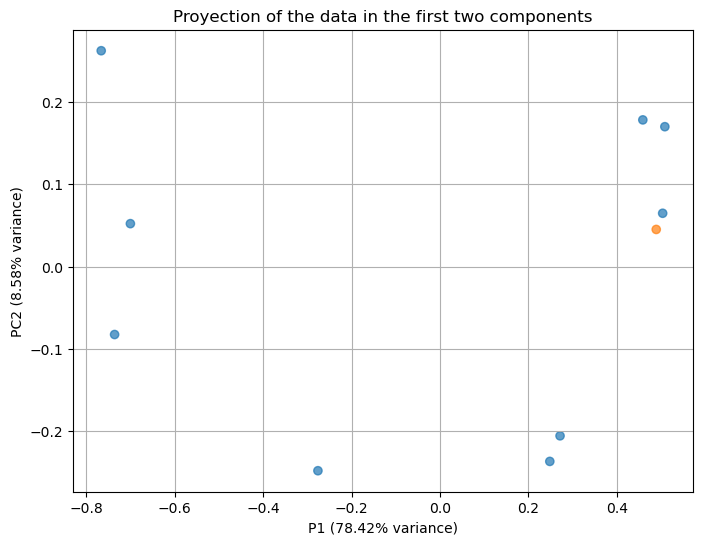

In [15]:
pca =plot_pca(frames, pca_components=10)

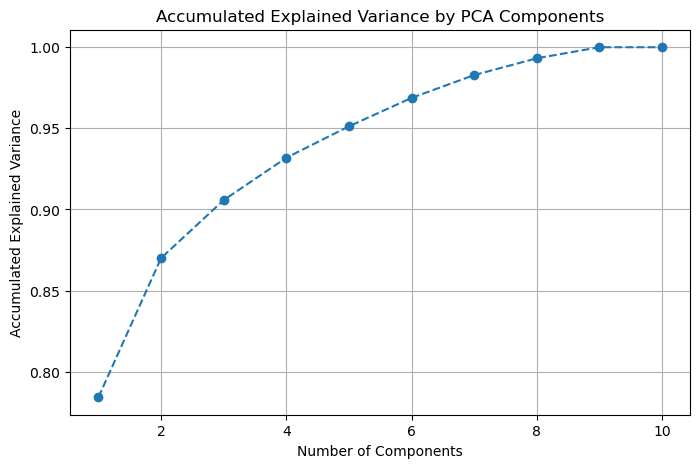

In [16]:
plot_explained_variance(pca)

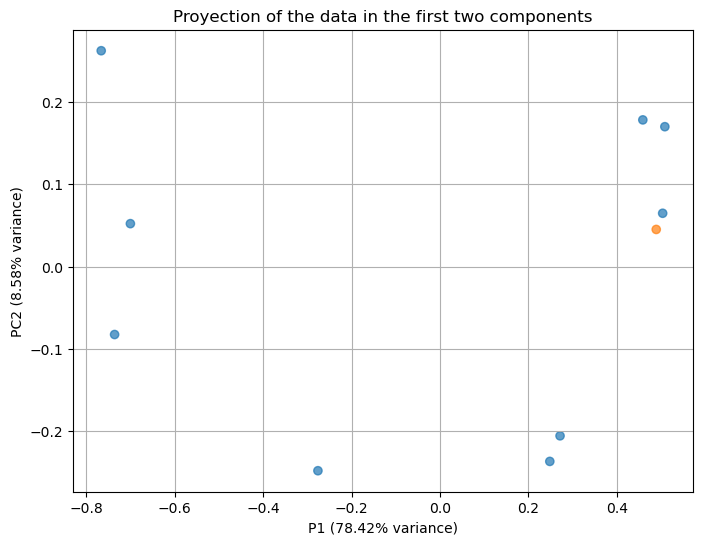

In [17]:
pca =plot_pca(frames, pca_components=2)

In [18]:
#clustering with kmeans
#dbscan = DBSCAN(eps=0.5, min_samples=2)
kmeans = KMeans(n_clusters=3, random_state=SEED)
kmeans.fit(pca.transform(frames['tensores']))
frames['clusters'] = kmeans.labels_

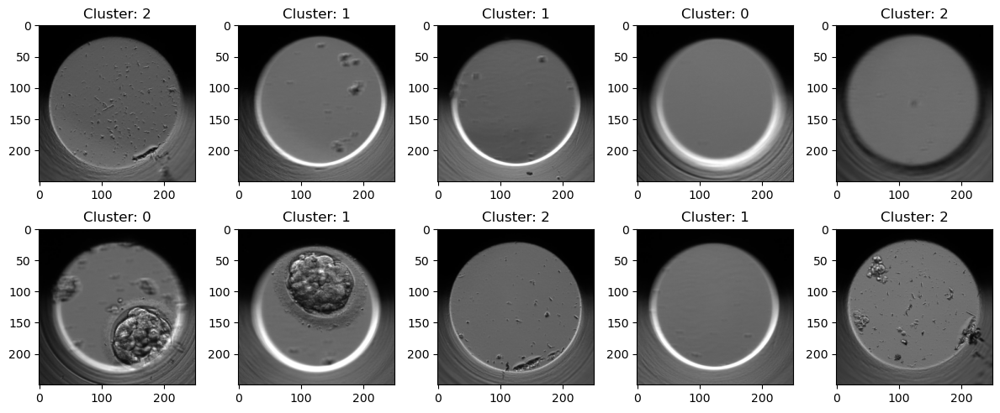

In [19]:
fig, axes = plt.subplots(2,5, figsize=(12, 5))
axes = axes.flatten()
for i in range(10):
    axes[i].imshow(image_frame(frames['files'][i], excel_path, t=121))
    axes[i].set_title(f"Cluster: {frames['clusters'][i]}")
plt.tight_layout()
plt.show()

In [20]:
frames1 = frame_ext(train_files, X_train, mask_train, y_train, t=70)
frames1['clusters'] = kmeans.predict(pca.transform(frames1['tensores']))

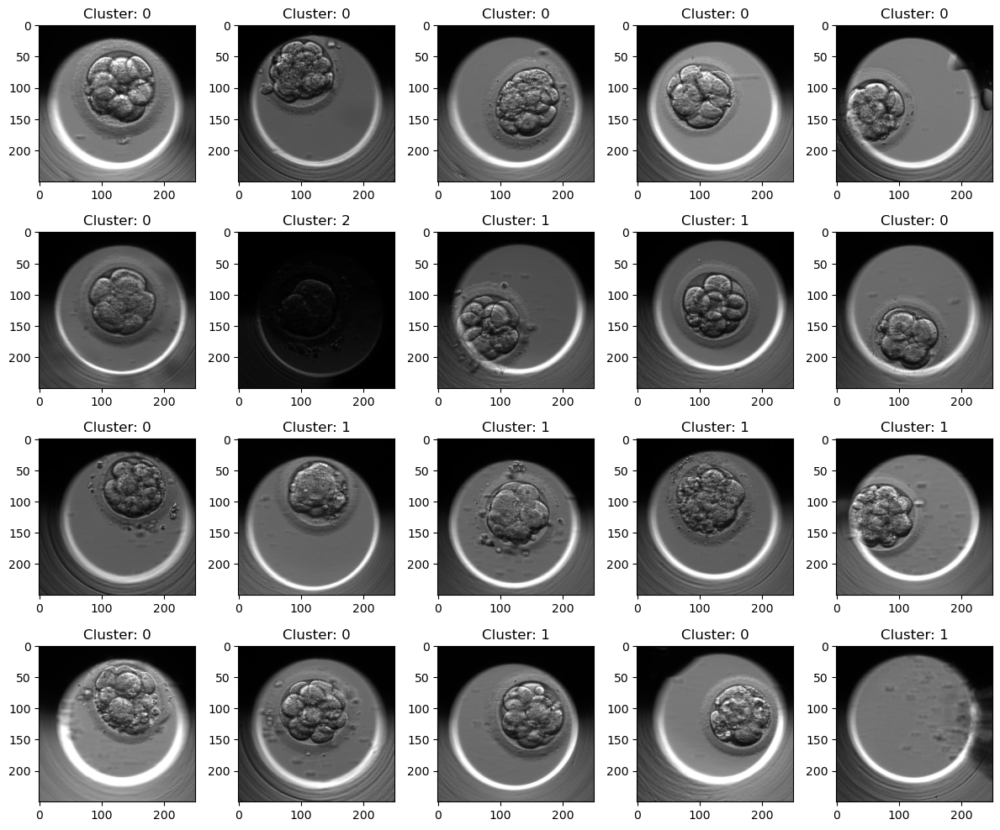

In [21]:
fig, axes = plt.subplots(4,5, figsize=(12, 10))
axes = axes.flatten()
for i in range(20):
    axes[i].imshow(image_frame(frames1['files'][i], excel_path, t=70))
    axes[i].set_title(f"Cluster: {frames1['clusters'][i]}")
plt.tight_layout()
plt.show()

### All frames of all videos

Plot all the frames from all the videos with the PCA values

In [14]:
ALL_FRAMES = {'files':[], 'tensores':[], 'labels':[], 'frame_n':[], 'mask':[]}
for i in range(214):
    frames = frame_ext(train_files, X_train, mask_train, y_train, t=i)
    ALL_FRAMES['files'].extend(frames['files'])
    ALL_FRAMES['tensores'].extend(frames['tensores'])
    ALL_FRAMES['labels'].extend(frames['labels'])
    ALL_FRAMES['frame_n'].extend([i for k in range(len(frames['files']))])

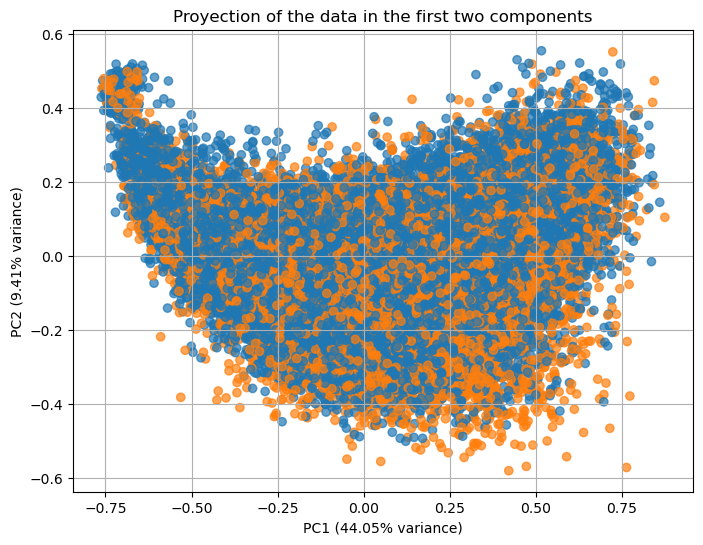

In [15]:
pca = plot_pca(ALL_FRAMES, pca_components=10)

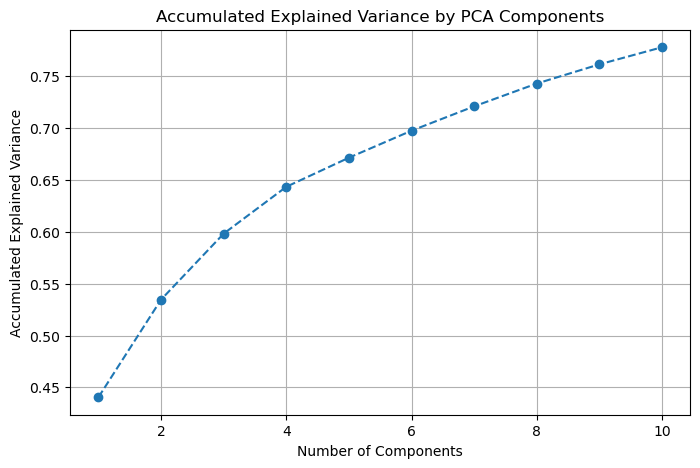

In [16]:
plot_explained_variance(pca)

In [17]:
clustering = KMeans(n_clusters=5, random_state=SEED)
clustering.fit(pca.transform(ALL_FRAMES['tensores']))
ALL_FRAMES['clusters'] = clustering.labels_

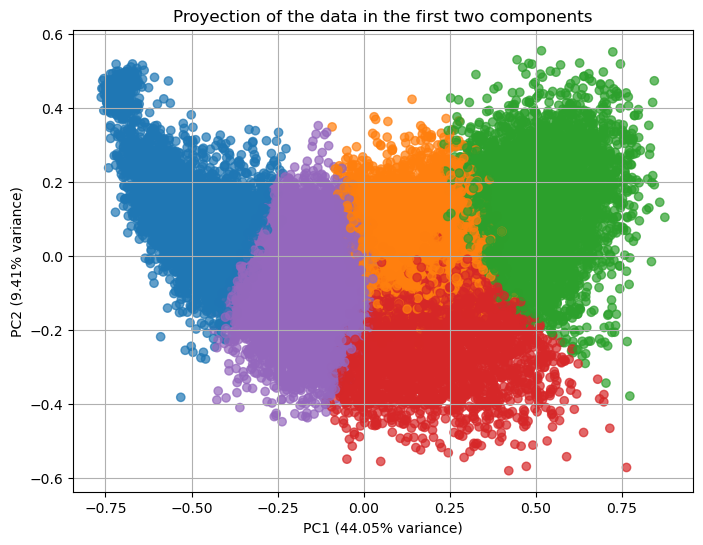

In [18]:
pca = plot_pca(ALL_FRAMES, pca_components=2, paint='clusters')

In [19]:
ALL_FRAMES['pca'] = pca.transform(ALL_FRAMES['tensores'])

In [20]:
np.unique(ALL_FRAMES['clusters'])

array([0, 1, 2, 3, 4], dtype=int32)

In [25]:
def plot_cluster(ALL_FRAMES, cluster_label, n_cols=5, max_frames=20):
    selected = ALL_FRAMES['clusters'] == cluster_label
    f = np.array(ALL_FRAMES['files'])[selected]
    lbl = np.array(ALL_FRAMES['labels'])[selected]
    t = np.array(ALL_FRAMES['frame_n'])[selected]
    pca = np.array(ALL_FRAMES['pca'])[selected]

    print(f"Mean PCA for cluster {cluster_label}: {np.mean(pca, axis=0)}")

    n_files = len(f)
    if n_files == 0:
        print(f"No files found for cluster {cluster_label}")
        return
    n_files = min(n_files, max_frames)
    n_rows = int(np.ceil(n_files / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.5 * n_cols, 2.5 * n_rows))
    axes = np.array(axes).reshape(-1)

    for i in range(n_files):
        axes[i].imshow(image_frame(f[i], excel_path, t=t[i]))
        axes[i].set_title(f"FHB: {lbl[i]}")
        axes[i].axis('off')

    for j in range(n_files, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

Mean PCA for cluster 0: [-0.47164754  0.09043695]


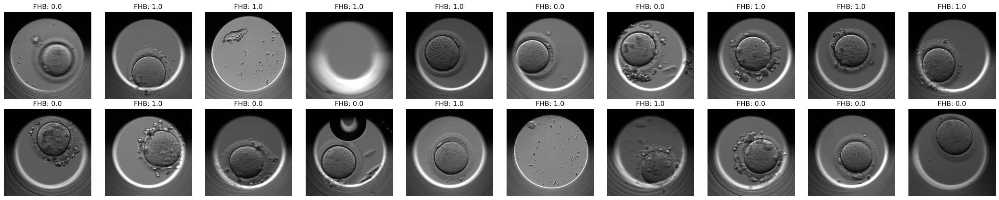

In [26]:
plot_cluster(ALL_FRAMES, 0, n_cols=10)

Mean PCA for cluster 1: [0.15615892 0.03604244]


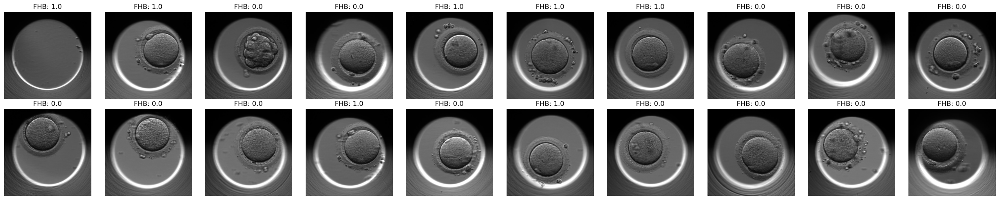

In [31]:
plot_cluster(ALL_FRAMES, 1, n_cols=10)

In [32]:
np.unique(ALL_FRAMES['clusters'], return_counts=True)

(array([0, 1, 2, 3, 4], dtype=int32),
 array([ 6612,  7948,  5744,  4302, 10526]))

Mean PCA for cluster 2: [0.48571886 0.12393573]


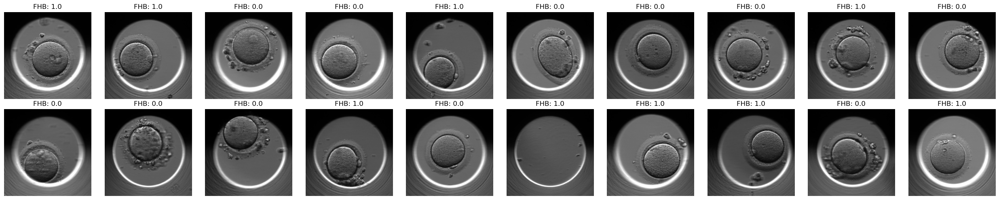

In [33]:
plot_cluster(ALL_FRAMES, 2, n_cols=10)

Mean PCA for cluster 3: [ 0.19802486 -0.21951829]


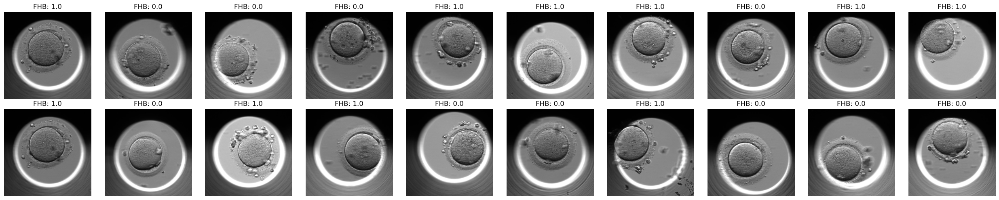

In [34]:
plot_cluster(ALL_FRAMES, 3, n_cols=10)

Mean PCA for cluster 4: [-0.16763154 -0.06193745]


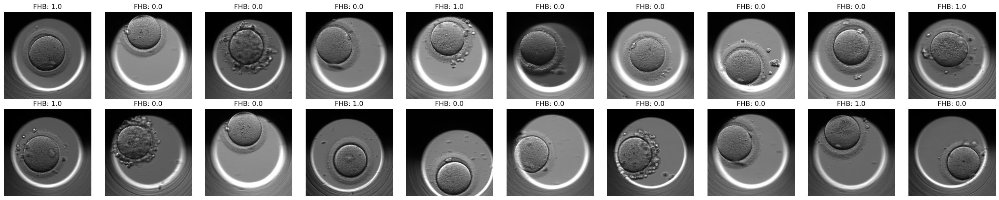

In [35]:
plot_cluster(ALL_FRAMES, 4, n_cols=10)

In [27]:
import umap
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1)
embedding = reducer.fit_transform(ALL_FRAMES['tensores'])  # features: (N_frames, D)

/home/mvillota/anaconda3/envs/torch_cuda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [28]:
ALL_FRAMES['umap'] = embedding

In [29]:
embedding 

array([[ 2.1179645,  8.406183 ],
       [-1.171844 ,  8.312798 ],
       [ 2.0650055,  8.044023 ],
       ...,
       [ 3.521278 , 13.48807  ],
       [ 3.54025  , 13.5027485],
       [ 3.531472 , 13.522039 ]], shape=(35132, 2), dtype=float32)

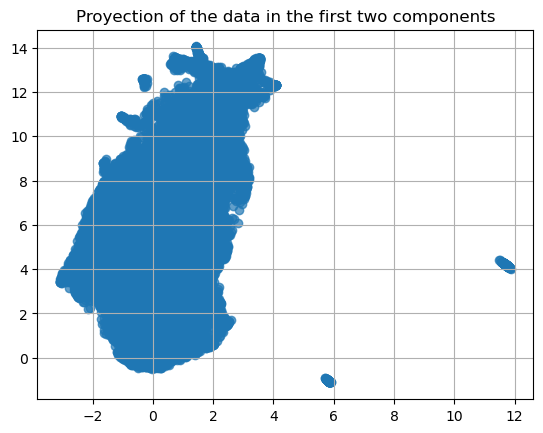

In [31]:
plt.scatter(embedding[:, 0], embedding[:, 1], alpha=0.7)
plt.title('Proyection of the data in the first two components')
plt.grid()
plt.show()

In [33]:
np.unique(ALL_FRAMES['frame_n'])

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

### VIDEO INDIVIDUAL

In [44]:
video = 0
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1)

frames = [X_train[video][i] for i in range(len(X_train[video])) if mask_train[video][i]]  # Solo frames válidos
t = [i for i in range(len(X_train[video])) if mask_train[video][i]]
embedding = reducer.fit_transform(frames)  

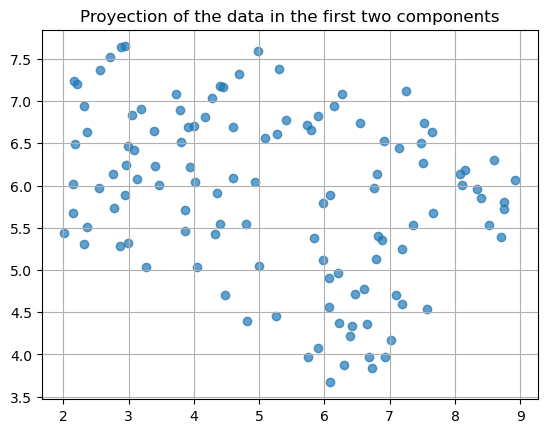

In [38]:
plt.scatter(embedding[:, 0], embedding[:, 1], alpha=0.7)
plt.title('Proyection of the data in the first two components')
plt.grid()
plt.show()

In [43]:
mini = min(embedding[:, 0])
maxi = max(embedding[:, 0])

list(embedding[:, 0]).index(mini), list(embedding[:, 0]).index(maxi)

(24, 91)

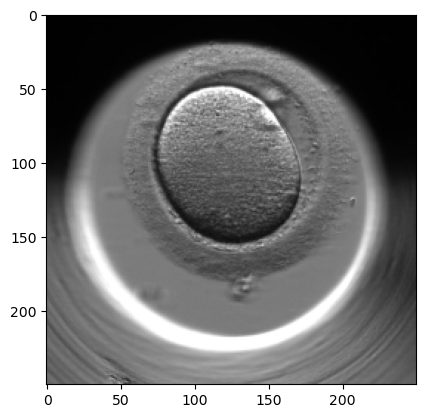

In [51]:
plt.imshow(image_frame(train_files[0], excel_path, t=25))

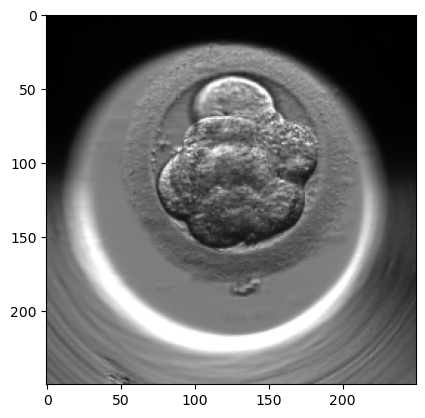

In [52]:
plt.imshow(image_frame(train_files[0], excel_path, t=91))

In [ ]:
normalized = []
for i in range(300):
    vid_feats = features[i * 214 : (i + 1) * 214]
    normalized.append(StandardScaler().fit_transform(vid_feats))
features_norm = np.vstack(normalized)

Mean PCA for cluster 2: [0.48571886 0.12393573]


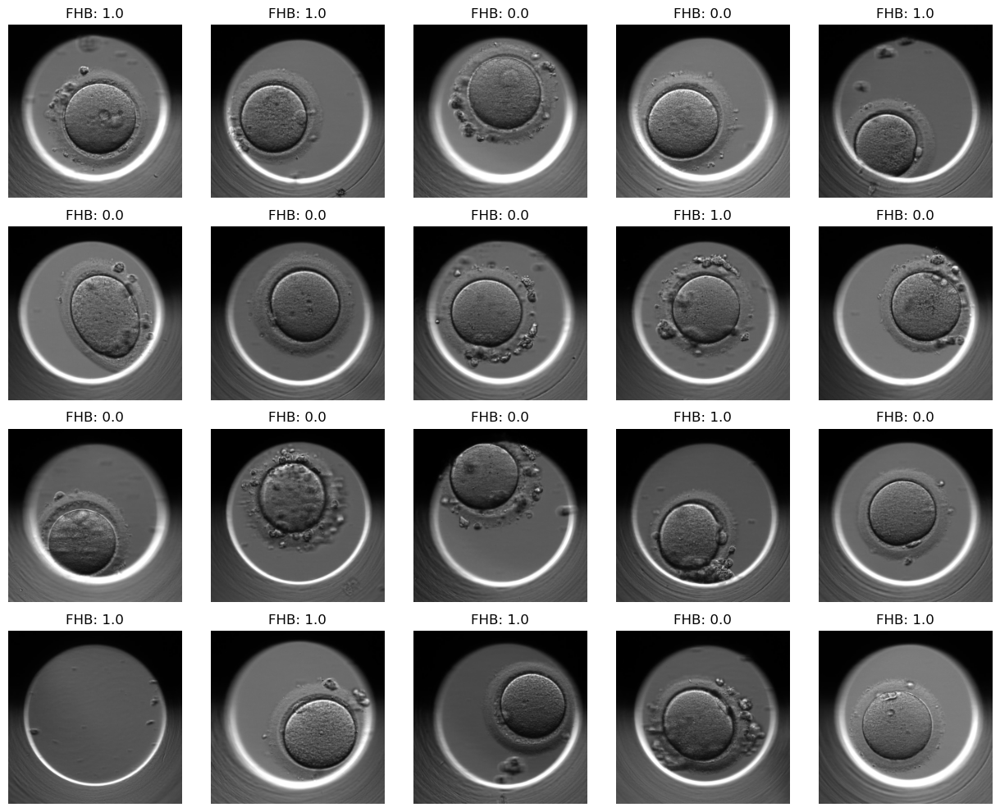

In [37]:
plot_cluster(ALL_FRAMES, 2)

Mean PCA for cluster 3: [ 0.19802486 -0.21951829]


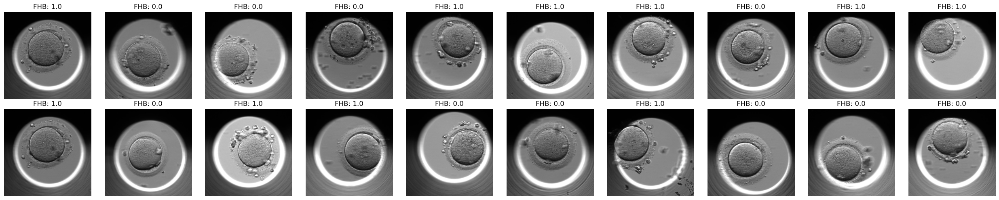

In [38]:
plot_cluster(ALL_FRAMES, 3, n_cols=10)

In [39]:
def plot_pca_frames_grid(X_train, X_train_mask,y_train,frames_to_plot: list[int] | None = None,
                         n_cols: int = 5,figsize_per_cell: tuple[float, float] = (3.5, 3.0),
                         alpha: float = 0.7,point_size: int = 20,
                         filename: str = "pca_frames_grid.png",
                         ):

    if frames_to_plot is None:
        frames_to_plot = list(range(20))
 
    n_frames = len(frames_to_plot)
    n_rows   = (n_frames + n_cols - 1) // n_cols
 
    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(figsize_per_cell[0] * n_cols, figsize_per_cell[1] * n_rows),
    )
    axes = np.array(axes).reshape(-1)   # aplanar para indexar fácil
 
    # Colores fijos por clase
    class_colors = {0: "#4C72B0", 1: "#DD8452"}
    class_labels = {0: "No latido", 1: "Latido"}
 
    for ax_idx, frame_idx in enumerate(frames_to_plot):
        ax = axes[ax_idx]
 
        # ── recoger embeddings válidos para este frame ──────────────────────
        vecs, labels = [], []
        for i in range(len(X_train)):
            if X_train_mask[i][frame_idx]:
                vecs.append(X_train[i][frame_idx].numpy())
                labels.append(int(y_train[i].item()))
 
        if len(vecs) < 4:   # muy pocos puntos → saltar
            ax.set_visible(False)
            continue
 
        vecs   = np.stack(vecs)
        labels = np.array(labels)
 
        # ── PCA ─────────────────────────────────────────────────────────────
        n_comp = min(2, vecs.shape[0] - 1, vecs.shape[1])
        pca    = PCA(n_components=n_comp)
        coords = pca.fit_transform(vecs)
 
        ev = pca.explained_variance_ratio_
        pc2_label = f"{ev[1]:.1%}" if n_comp == 2 else "N/A"
 
        # ── scatter por clase ────────────────────────────────────────────────
        for cls, color in class_colors.items():
            mask = labels == cls
            if mask.sum() == 0:
                continue
            ax.scatter(
                coords[mask, 0],
                coords[mask, 1] if n_comp == 2 else np.zeros(mask.sum()),
                c=color, label=class_labels[cls],
                alpha=alpha, s=point_size, linewidths=0,
            )
 
        ax.set_title(
            f"Frame {frame_idx}  |  n={len(vecs)}\n"
            f"PC1={ev[0]:.1%}  PC2={pc2_label}",
            fontsize=8, pad=4,
        )
        ax.set_xlabel("PC1", fontsize=7)
        ax.set_ylabel("PC2", fontsize=7)
        ax.tick_params(labelsize=6)
        ax.grid(True, linewidth=0.4, alpha=0.5)
 
    # Ocultar ejes sobrantes
    for ax in axes[n_frames:]:
        ax.set_visible(False)
 
    # Leyenda global arriba a la derecha
    handles = [
        plt.Line2D([0], [0], marker="o", color="w",
                   markerfacecolor=c, markersize=7, label=l)
        for l, c in zip(class_labels.values(), class_colors.values())
    ]
    fig.legend(
        handles, list(class_labels.values()),
        loc="upper right", fontsize=9,
        title="Clase", title_fontsize=9,
        framealpha=0.9,
    )
 
    fig.suptitle(
        "PCA por frame — proyección en PC1 × PC2",
        fontsize=13, fontweight="bold", y=1.01,
    )
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Guardado → {filename}")

In [40]:
len(X_train)

360

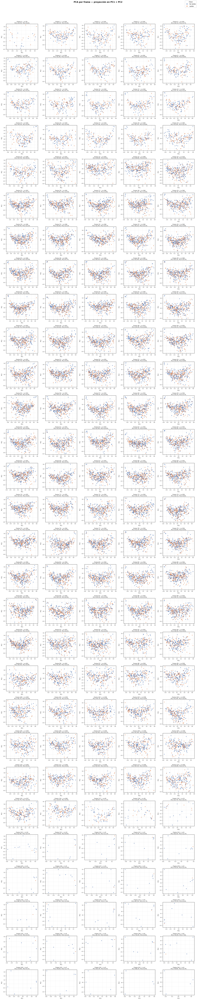

Guardado → pca_frames_grid.png


In [41]:
plot_pca_frames_grid(X_train, mask_train, y_train, frames_to_plot=list(range(214)), n_cols=5)

In [42]:
plt.imshow(image_frame(frames['files'][16], excel_path, t=24))

IndexError: list index out of range

Reading video: ../Datasets/Processed/Oslo_processed/videos/D2018.11.01_S01154_I0427_D_Well_02.avi
Reading video: ../Datasets/Processed/Oslo_processed/videos/D2017.11.15_S00917_I0427_D_Well_03.avi
Reading video: ../Datasets/Processed/Oslo_processed/videos/D2016.11.25_S0664_I427_Well_06.avi
Reading video: ../Datasets/Processed/Oslo_processed/videos/D2018.08.20_S01074_I0427_D_Well_07.avi


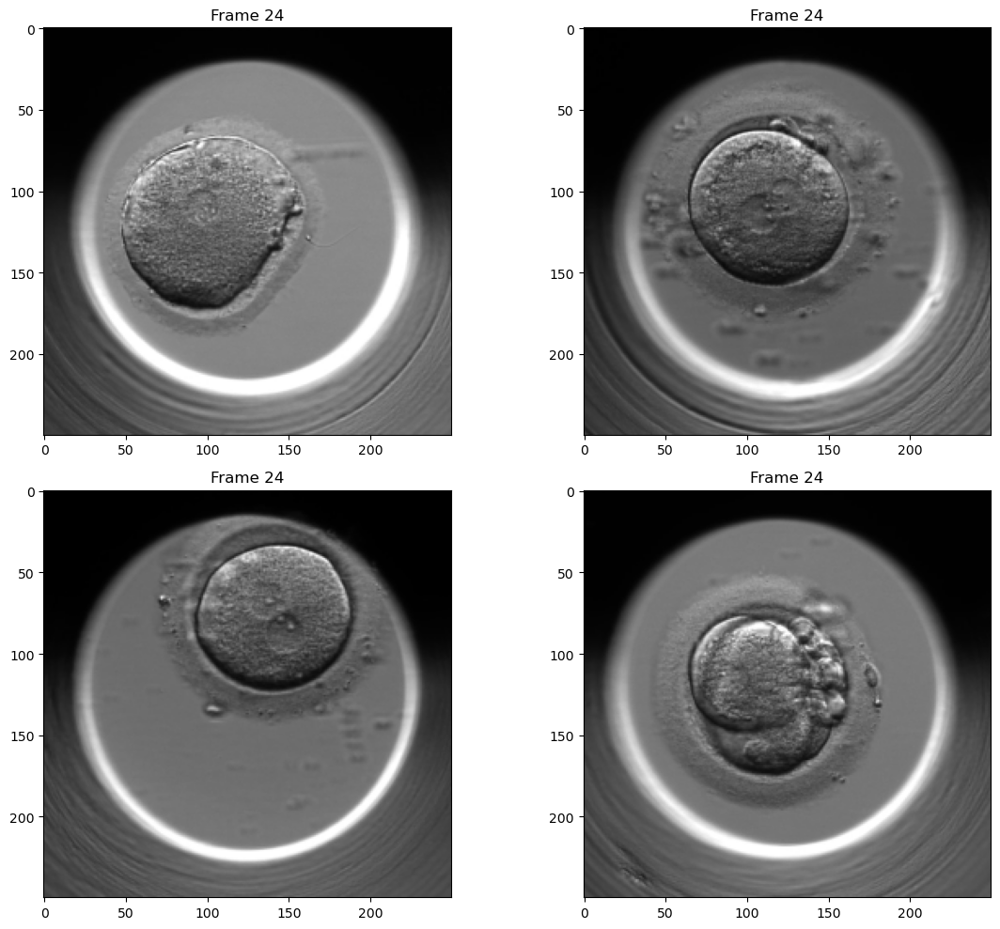

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
axes[0].imshow(image_frame(frames['files'][3], excel_path, t=24))
axes[0].set_title("Frame 24")
axes[1].imshow(image_frame(frames['files'][16], excel_path, t=24))
axes[1].set_title("Frame 24")
axes[2].imshow(image_frame(frames['files'][69], excel_path, t=24))
axes[2].set_title("Frame 24")
axes[3].imshow(image_frame(frames['files'][178], excel_path, t=24))
axes[3].set_title("Frame 24")
plt.tight_layout()
plt.show()

In [ ]:
frames = frame_ext(train_files, X_train, mask_train, y_train, t=24)

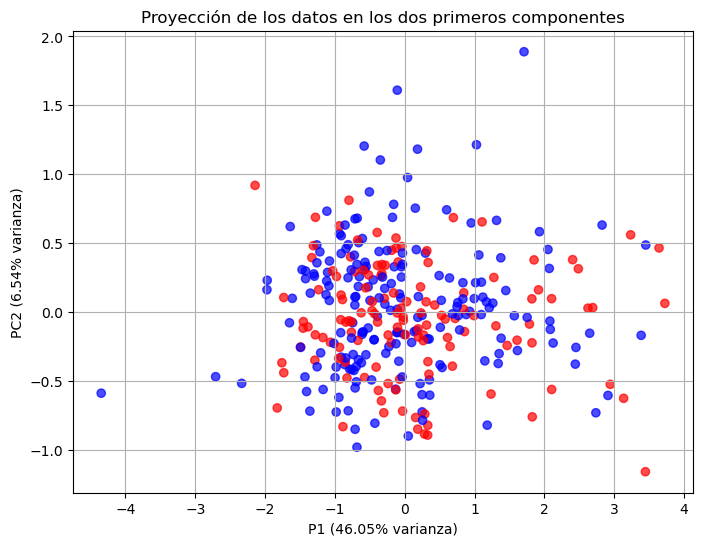

In [ ]:
pca =plot_pca(frames, pca_components=10)

# Clustering es capaz de separar los distintos desarrollos??

In [ ]:
#clustering with kmeans
from sklearn.cluster import KMeans, DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=2)
kmeans = KMeans(n_clusters=2, random_state=SEED)
kmeans.fit(frames['tensores'])
frames['clusters'] = kmeans.labels_

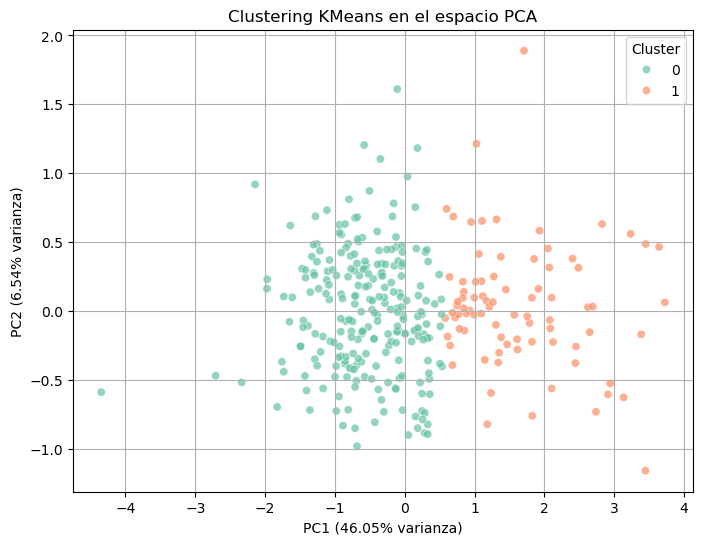

In [ ]:
#plot the clusters in the PCA space
X_pca = pca.transform(frames['tensores'])
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=frames['clusters'], palette='Set2', alpha=0.7)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} varianza)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} varianza)')
plt.title('Clustering KMeans en el espacio PCA')
plt.legend(title='Cluster')
plt.grid()
plt.show()

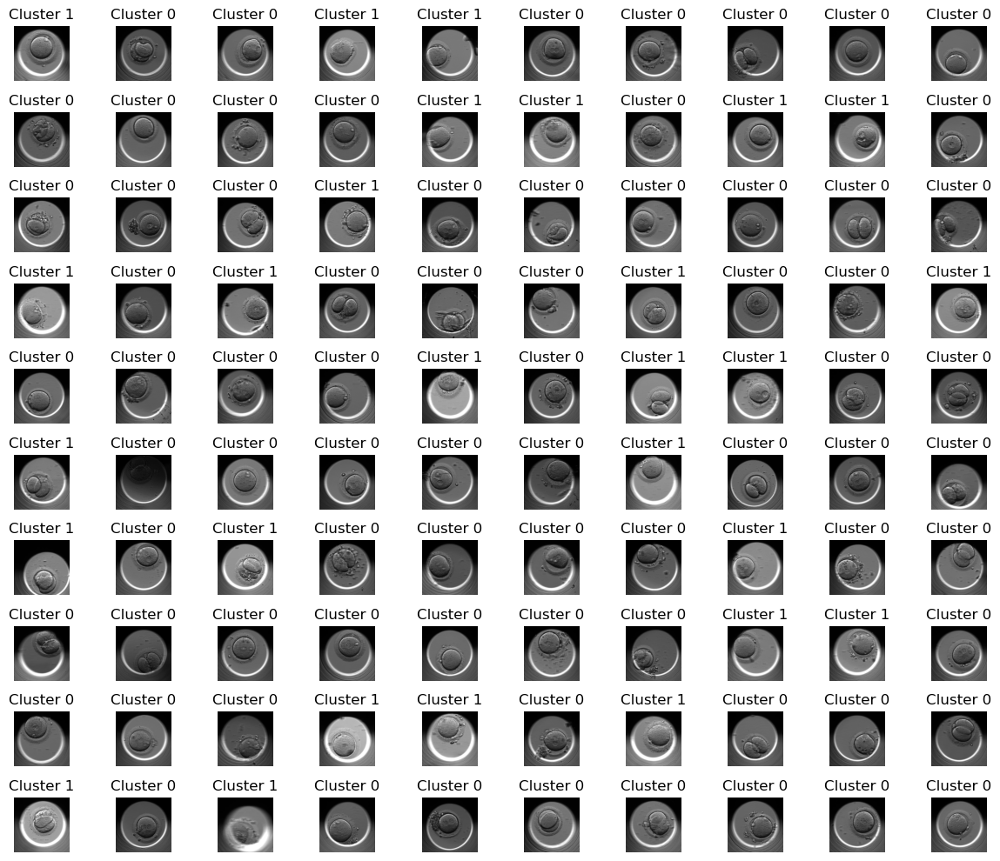

In [ ]:
fig, axes = plt.subplots(10, 10, figsize=(12, 10))
axes = axes.flatten()
for i in range(100):
    axes[i].imshow(image_frame(frames['files'][i], excel_path, t=24))
    axes[i].set_title(f"Cluster {frames['clusters'][i]}")
    axes[i].axis('off')
plt.tight_layout()
plt.show() 

In [ ]:
X_pca = pca.transform(frames['tensores'])

In [ ]:
X_pca

array([[ 0.99105435, -0.03112264,  0.67773413, ..., -0.35883209,
        -0.19156086, -0.33914791],
       [-1.17676251, -0.75215307, -0.08534889, ...,  0.02058772,
        -0.23833278, -0.15812595],
       [ 0.36381657, -0.04171284,  0.02574269, ...,  0.12994326,
         0.06749672,  0.1791773 ],
       ...,
       [ 1.80225061,  0.43323967,  0.40534436, ..., -0.164696  ,
        -0.01092435, -0.10073652],
       [-0.15826849, -0.24295503,  0.57262681, ...,  0.20278585,
         0.32435207, -0.17822645],
       [-0.89511763, -0.00231381, -0.2362034 , ..., -0.17819407,
         0.21526309,  0.05035261]], shape=(355, 10))

Reading video: ../Datasets/Processed/Oslo_processed/videos/D2018.05.04_S01114_I0426_D_Well_03.avi


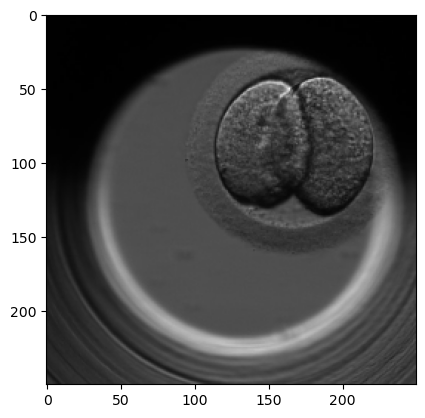

In [ ]:
plt.imshow(image_frame(frames['files'][188], excel_path, t=28))